<a href="https://colab.research.google.com/github/cmauriciocrescente-upc/Dataset-en-Colab/blob/main/Actividad_1_Temperaturas_Regresion_Lineal_19_08_26.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Actividad 1er link

In [ ]:
# IMPORTANT: RUN THIS CELL IN ORDER TO IMPORT YOUR KAGGLE DATA SOURCES,
# THEN FEEL FREE TO DELETE THIS CELL.
# NOTE: THIS NOTEBOOK ENVIRONMENT DIFFERS FROM KAGGLE'S PYTHON
# ENVIRONMENT SO THERE MAY BE MISSING LIBRARIES USED BY YOUR
# NOTEBOOK.
import kagglehub
budincsevity_szeged_weather_path = kagglehub.dataset_download('budincsevity/szeged-weather')

print('Data source import complete.')


Using Colab cache for faster access to the 'szeged-weather' dataset.
Data source import complete.


# Linear regression (predicting a continuous value):

*** Question:**
>     Weather in Szeged 2006-2016: Is there a relationship between humidity and temperature? What about between humidity and apparent temperature? Can you predict the apparent temperature given the humidity?

In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load in

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score, cross_val_predict
import operator

# Input data files are available in the "../input/" directory.
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# Any results you write to the current directory are saved as output.

/kaggle/input/szeged-weather/weatherHistory.csv


In [ ]:
import kagglehub

# Download latest version
weatherHistory = kagglehub.dataset_download("budincsevity/szeged-weather")

print("Path to dataset files:", weatherHistory)

Using Colab cache for faster access to the 'szeged-weather' dataset.
Path to dataset files: /kaggle/input/szeged-weather


In [ ]:
weatherHistory = pd.read_csv("/kaggle/input/szeged-weather/weatherHistory.csv")

In [ ]:
weatherHistory.head(2)

,Formatted Date,Summary,Precip Type,Temperature (C),Apparent Temperature (C),Humidity,Wind Speed (km/h),Wind Bearing (degrees),Visibility (km),Loud Cover,Pressure (millibars),Daily Summary
0,2006-04-01 00:00:00.000 +0200,Partly Cloudy,rain,9.472222,7.388889,0.89,14.1197,251.0,15.8263,0.0,1015.13,Partly cloudy throughout the day.
1,2006-04-01 01:00:00.000 +0200,Partly Cloudy,rain,9.355556,7.227778,0.86,14.2646,259.0,15.8263,0.0,1015.63,Partly cloudy throughout the day.


In [ ]:
weatherHistory.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 96453 entries, 0 to 96452
Data columns (total 12 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Formatted Date            96453 non-null  object 
 1   Summary                   96453 non-null  object 
 2   Precip Type               95936 non-null  object 
 3   Temperature (C)           96453 non-null  float64
 4   Apparent Temperature (C)  96453 non-null  float64
 5   Humidity                  96453 non-null  float64
 6   Wind Speed (km/h)         96453 non-null  float64
 7   Wind Bearing (degrees)    96453 non-null  float64
 8   Visibility (km)           96453 non-null  float64
 9   Loud Cover                96453 non-null  float64
 10  Pressure (millibars)      96453 non-null  float64
 11  Daily Summary             96453 non-null  object 
dtypes: float64(8), object(4)
memory usage: 8.8+ MB


In [ ]:
weatherHistory.describe().T

,count,mean,std,min,25%,50%,75%,max
Temperature (C),96453.0,11.932678,9.551546,-21.822222,4.688889,12.0000,18.838889,39.905556
Apparent Temperature (C),96453.0,10.855029,10.696847,-27.716667,2.311111,12.0000,18.838889,39.344444
Humidity,96453.0,0.734899,0.195473,0.000000,0.600000,0.7800,0.890000,1.000000
Wind Speed (km/h),96453.0,10.810640,6.913571,0.000000,5.828200,9.9659,14.135800,63.852600
Wind Bearing (degrees),96453.0,187.509232,107.383428,0.000000,116.000000,180.0000,290.000000,359.000000
Visibility (km),96453.0,10.347325,4.192123,0.000000,8.339800,10.0464,14.812000,16.100000
Loud Cover,96453.0,0.000000,0.000000,0.000000,0.000000,0.0000,0.000000,0.000000
Pressure (millibars),96453.0,1003.235956,116.969906,0.000000,1011.900000,1016.4500,1021.090000,1046.380000


In [ ]:
# Extract 3 columns 'Temperature (C)','Apparent Temperature (C)', 'Humidity' for pure and better showing
weatherHistory_df = weatherHistory[['Temperature (C)','Apparent Temperature (C)', 'Humidity']]

# And called again
weatherHistory_df.columns = ['Temperature', 'Apparent_Temperature', 'Humidity']

In [ ]:
weatherHistory_df = weatherHistory_df[:][:500]      # lets take limit for speed regression calculating
weatherHistory_df.head(2)

,Temperature,Apparent_Temperature,Humidity
0,9.472222,7.388889,0.89
1,9.355556,7.227778,0.86


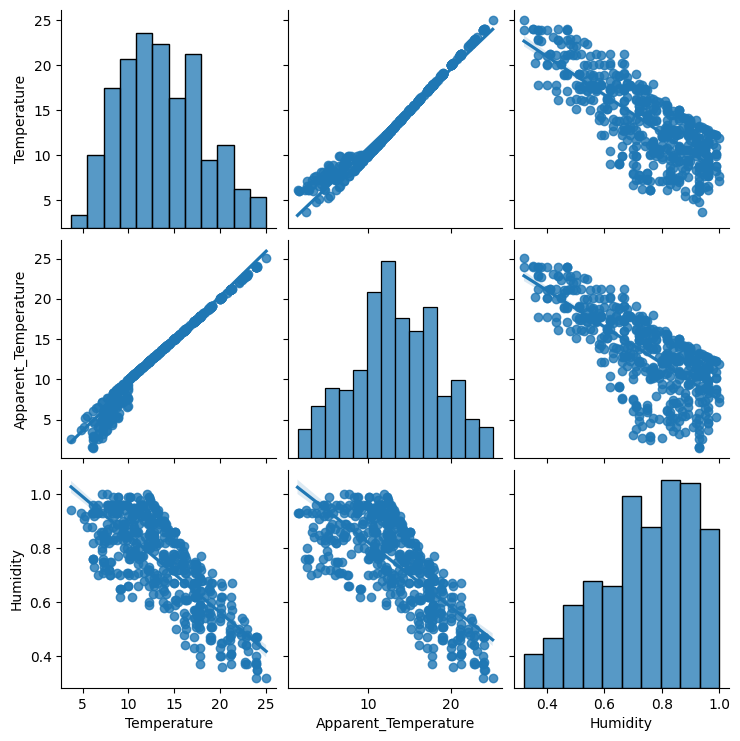

In [ ]:
# See picture with scatter or plot method

sns.pairplot(weatherHistory_df, kind="reg")

In [ ]:
# see how many null values we have

weatherHistory_df.isnull().sum()

,0
Temperature,0
Apparent_Temperature,0
Humidity,0


In [ ]:
# Features chose

y = np.array(weatherHistory_df['Humidity']).reshape(-1, 1)
X = np.array(weatherHistory_df['Apparent_Temperature']).reshape(-1, 1)

# Chosen just 'Apparent_Temperature' feature if you want can also for 'Temperature' feature

In [ ]:
# Split data as %20 is test and %80 is train set

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.20, random_state = 42)

# 1.Linear Regression

In [ ]:
from sklearn.linear_model import LinearRegression

lin_df = LinearRegression()
lin_df.fit(X_train, y_train)

LinearRegression()

In [ ]:
y_pred = lin_df.predict(X_test)                                     # Predict Linear Model
accuracy_score = lin_df.score(X_test, y_test)                       # Accuracy score
print("Linear Regression Model Accuracy Score: " + "{:.1%}".format(accuracy_score))

Linear Regression Model Accuracy Score: 54.4%


In [ ]:
from sklearn.metrics import mean_squared_error,r2_score

print("R2 Score: " +"{:.3}".format(r2_score(y_test, y_pred)));

R2 Score: 0.544


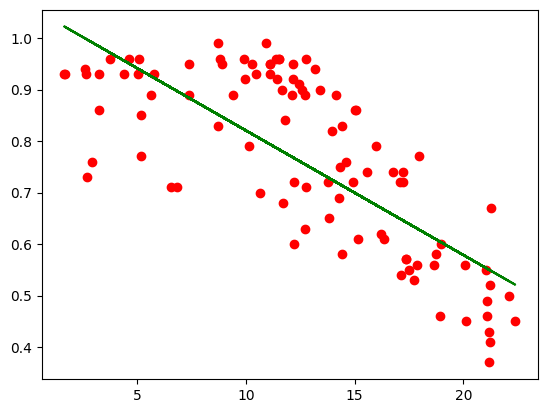

In [ ]:
# Finally draw figure of Linear Regression Model

plt.scatter(X_test, y_test, color='r')
plt.plot(X_test, y_pred, color='g')
plt.show()

# 2.Multiple Linear Regression

In [ ]:
mlin_df = LinearRegression()
mlin_df = mlin_df.fit(X_train, y_train)
mlin_df.intercept_       # constant b0
mlin_df.coef_            # variable coefficient

array([[-0.02416254]])

In [ ]:
y_pred = mlin_df.predict(X_train)                                      # predict Multi linear Reg model
rmse = np.sqrt(mean_squared_error(y_train, mlin_df.predict(X_train)))
print("RMSE Score for Test set: " +"{:.2}".format(rmse))
print("R2 Score for Test set: " +"{:.3}".format(r2_score(y_train, y_pred)));      # this is test error score

RMSE Score for Test set: 0.11
R2 Score for Test set: 0.539


## 2.1.Multiple Linear Regression Model Tunning

In [ ]:
# cross validation method is giving better and clear result

cross_val_score(mlin_df, X, y, cv=10, scoring = 'r2').mean()

np.float64(-0.013020366510679882)

In [ ]:
mlin_df.score(X_train, y_train)      # r2 value

0.5386375277111362

In [ ]:
np.sqrt(-cross_val_score(mlin_df,
                X_train,
                y_train,
                cv=10,
                scoring = 'neg_mean_squared_error')).mean()

np.float64(0.11291532622319658)

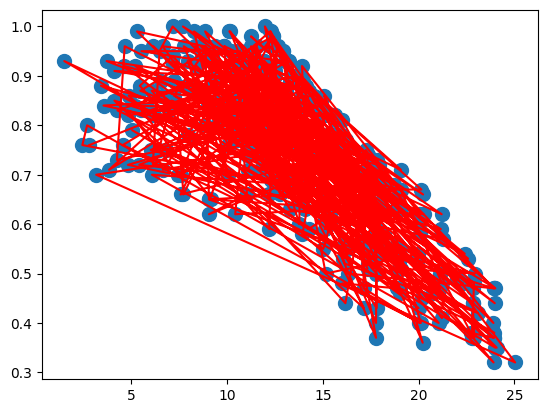

In [ ]:
# Finally draw figure of Multiple Linear Regression Model

plt.scatter(X_train, y_train, s=100)

# sort the values of x before line plot
sort_axis = operator.itemgetter(0)
sorted_zip = sorted(zip(X_train,y_pred), key=sort_axis)
X_test, y_pred = zip(*sorted_zip)
plt.plot(X_train, y_train, color='r')
plt.show()

* This was just for train set and you can also do for test set.

# 3.Polynomial Regression

In [ ]:
from sklearn.preprocessing import PolynomialFeatures

poly_df = PolynomialFeatures(degree = 5)
transform_poly = poly_df.fit_transform(X_train)

linreg2 = LinearRegression()
linreg2.fit(transform_poly,y_train)

polynomial_predict = linreg2.predict(transform_poly)


In [ ]:
rmse = np.sqrt(mean_squared_error(y_train,polynomial_predict))
r2 = r2_score(y_train,polynomial_predict)
print("RMSE Score for Test set: " +"{:.2}".format(rmse))
print("R2 Score for Test set: " +"{:.2}".format(r2))

RMSE Score for Test set: 0.095
R2 Score for Test set: 0.67


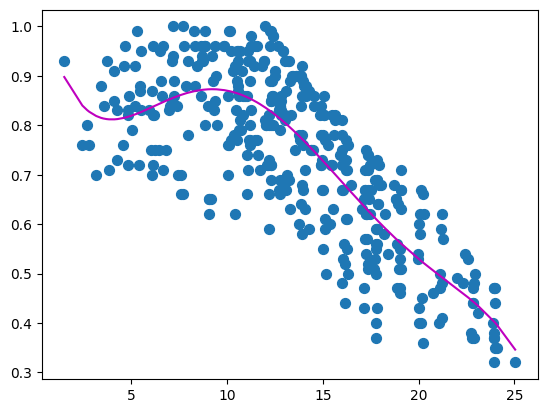

In [ ]:
plt.scatter(X_train, y_train, s=50)
# sort the values of x before line plot
sort_axis = operator.itemgetter(0)
sorted_zip = sorted(zip(X_train,polynomial_predict), key=sort_axis)
X_train, polynomial_predict = zip(*sorted_zip)
plt.plot(X_train, polynomial_predict, color='m')
plt.show()

* This was just for train set and you can also do for test set.

# 4.Decision Tree Regression

In [ ]:
from sklearn.tree import DecisionTreeRegressor

dt_reg = DecisionTreeRegressor()          # create  DecisionTreeReg with sklearn
dt_reg.fit(X_train,y_train)

DecisionTreeRegressor()

In [ ]:
dt_predict = dt_reg.predict(X_train)
#dt_predict.mean()

/tmp/ipykernel_1036/537478225.py:2: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  X_grid = np.arange(min(np.array(X_train)),max(np.array(X_train)), 0.01)


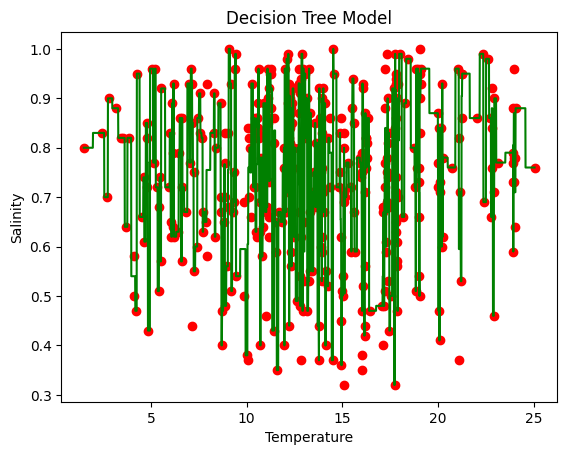

In [ ]:
plt.scatter(X_train,y_train, color="red")                           # scatter draw
X_grid = np.arange(min(np.array(X_train)),max(np.array(X_train)), 0.01)
X_grid = X_grid.reshape((len(X_grid), 1))
plt.plot(X_grid,dt_reg.predict(X_grid),color="g")                 # line draw
plt.xlabel("Temperature")
plt.ylabel("Salinity")
plt.title("Decision Tree Model")
plt.show()

In [ ]:
rmse = np.sqrt(mean_squared_error(y_train,dt_predict))
r2 = r2_score(y_train,dt_predict)
print("RMSE Score for Test set: " +"{:.2}".format(rmse))
print("R2 Score for Test set: " +"{:.2}".format(r2))

RMSE Score for Test set: 0.062
R2 Score for Test set: 0.86


* This was just for train set and you can also do for test set.

# 5.Random Forest Model

In [ ]:
from sklearn.ensemble import RandomForestRegressor

rf_reg = RandomForestRegressor(n_estimators=5, random_state=0)
rf_reg.fit(X_train,y_train)
rf_predict = rf_reg.predict(X_train)
#rf_predict.mean()

/usr/local/lib/python3.13/dist-packages/sklearn/base.py:1389: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)


/tmp/ipykernel_1036/1345776410.py:2: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  X_grid = np.arange(min(np.array(X_train)),max(np.array(X_train)), 0.01)


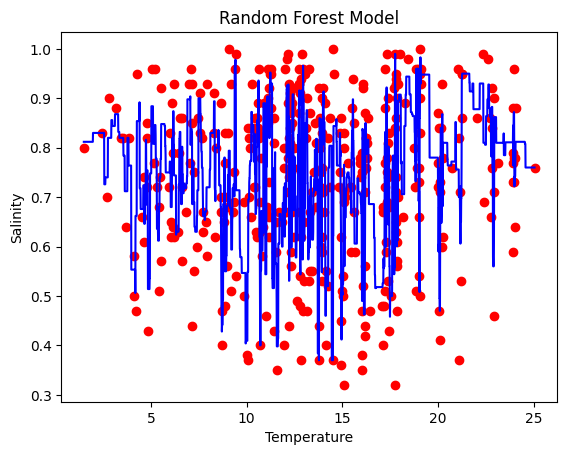

In [ ]:
plt.scatter(X_train,y_train, color="red")                           # scatter draw
X_grid = np.arange(min(np.array(X_train)),max(np.array(X_train)), 0.01)
X_grid = X_grid.reshape((len(X_grid), 1))
plt.plot(X_grid,rf_reg.predict(X_grid),color="b")                 # line draw
plt.xlabel("Temperature")
plt.ylabel("Salinity")
plt.title("Random Forest Model")
plt.show()

In [ ]:
rmse = np.sqrt(mean_squared_error(y_train,rf_predict))
r2 = r2_score(y_train,rf_predict)
print("RMSE Score for Test set: " +"{:.2}".format(rmse))
print("R2 Score for Test set: " +"{:.2}".format(r2))

RMSE Score for Test set: 0.1
R2 Score for Test set: 0.61


* This was just for train set and you can also do for test set.

**Result:** When we revise 5 models, best one is Decision Tree Regression Model with %86 accuracy score.

# Actividad 2do Link

In [ ]:
# IMPORTANT: RUN THIS CELL IN ORDER TO IMPORT YOUR KAGGLE DATA SOURCES,
# THEN FEEL FREE TO DELETE THIS CELL.
# NOTE: THIS NOTEBOOK ENVIRONMENT DIFFERS FROM KAGGLE'S PYTHON
# ENVIRONMENT SO THERE MAY BE MISSING LIBRARIES USED BY YOUR
# NOTEBOOK.
import kagglehub
smid80_weatherww2_path = kagglehub.dataset_download('smid80/weatherww2')

print('Data source import complete.')


Using Colab cache for faster access to the 'weatherww2' dataset.
Data source import complete.


In [ ]:
#from google.colab import files
#files.upload()

{}

In [ ]:
# Install dependencies as needed:
# pip install kagglehub[pandas-datasets]
import kagglehub
from kagglehub import KaggleDatasetAdapter

# Set the path to the file you'd like to load
file_path = "Summary of Weather.csv"

# Load the latest version
df = kagglehub.load_dataset(
  KaggleDatasetAdapter.PANDAS,
  "smid80/weatherww2",
  file_path,
  # Provide any additional arguments like
  # sql_query or pandas_kwargs. See the
  # documenation for more information:
  # https://github.com/Kaggle/kagglehub/blob/main/README.md#kaggledatasetadapterpandas
)

print("First 5 records:", df.head())

/tmp/ipykernel_1036/4030791235.py:10: DeprecationWarning: Use dataset_load() instead of load_dataset(). load_dataset() will be removed in a future version.
  df = kagglehub.load_dataset(


Using Colab cache for faster access to the 'weatherww2' dataset.
First 5 records:      STA      Date Precip  WindGustSpd    MaxTemp    MinTemp   MeanTemp  \
0  10001  1942-7-1  1.016          NaN  25.555556  22.222222  23.888889   
1  10001  1942-7-2      0          NaN  28.888889  21.666667  25.555556   
2  10001  1942-7-3   2.54          NaN  26.111111  22.222222  24.444444   
3  10001  1942-7-4   2.54          NaN  26.666667  22.222222  24.444444   
4  10001  1942-7-5      0          NaN  26.666667  21.666667  24.444444   

  Snowfall PoorWeather  YR  ...  FB  FTI ITH  PGT  TSHDSBRSGF  SD3  RHX  RHN  \
0      0.0         NaN  42  ... NaN  NaN NaN  NaN         NaN  NaN  NaN  NaN   
1      0.0         NaN  42  ... NaN  NaN NaN  NaN         NaN  NaN  NaN  NaN   
2      0.0         NaN  42  ... NaN  NaN NaN  NaN         NaN  NaN  NaN  NaN   
3      0.0         NaN  42  ... NaN  NaN NaN  NaN         NaN  NaN  NaN  NaN   
4      0.0         NaN  42  ... NaN  NaN NaN  NaN         NaN  NaN 

/usr/local/lib/python3.13/dist-packages/kagglehub/pandas_datasets.py:92: DtypeWarning: Columns (7,8,18,25) have mixed types. Specify dtype option on import or set low_memory=False.
  result = read_function(


In [ ]:
# ---Comento este original para guardar el codigo-----
# --- Import & Apply CSS File ---
# from IPython.core.display import display, HTML, Javascript

# kagglehub.dataset_download('caesarmario/colab-kaggle-stylesheet')

# def apply_css():
#    return HTML('<style>' + open('/kaggle/input/caesarmario/css/2023/css_ww2_revamp.css', 'r').read() + '</style>')
# apply_css()

<!--- Project Title --->
<span class="dates">II.XXIV.MMXXIII | @caesarmario</span><br>
<span class="title-normal">World War II </span>
<span class="title-highlight">Maximum Temperatures Prediction</span><br>
<span class="subtitle">using Linear Regression</span>
<hr>
<!-- Hello world 👋. Thank you so much for downloading/forking my codes/works. If you like my works, please support me by giving upvotes and comments on my Kaggle profile (https://www.kaggle.com/caesarmario/). Thank you so much and have a great day 😆👍. More about me: https://linktr.ee/caesarmario_ -->

# <div class="header1">1. | Introduction 👋</div>
<center>
    <img src="https://images.unsplash.com/photo-1545289882-ed8ed20078be?ixid=MnwxMjA3fDB8MHxwaG90by1wYWdlfHx8fGVufDB8fHx8&ixlib=rb-1.2.1&auto=format&fit=crop&w=1169&q=80" alt="Temperatures" width="80%">
</center>

## <div class="header2">🤔 Dataset Problems</div>
<div class="explain-box">
    The dataset contains <mark><b>information on weather conditions recorded on each day</b></mark> at various weather stations around the world. Information includes <b>precipitation, snowfall, temperatures, wind speed and whether the day included thunder storms or other poor weather conditions</b>. In this case, <mark><b>linear regression model will be implemented to predict the maximum temperature</b></mark> based on minimum temperature.
</div>

## <div class="header2">📌 Notebook Objectives</div>
<div class="explain-box">
    This notebook <b>aims</b> to:
    <ul>
        <li><mark><b>Perform initial data exploration and EDA</b></mark>.</li>
        <li><mark><b>Implement linear regression model</b></mark> to predict the temperature.</li>
        <li><mark><b>Evaluate linear regression model</b></mark> that has been implemented.</li>
    </ul>
</div>

## <div class="header2">👨‍💻 Machine Learning Model</div>
<div class="explain-box">
    The <b>model</b> used in this notebook:
    <ol>
        <li><b>Linear Regression</b>.</li>
    </ol>
</div>

## <div class="header2">🧾 Dataset Description</div>
<div class="explain-box">
    The following is the <b>structure of the dataset</b>.<br>
    
<table style="font-family: Libre Baskerville; font-weight: 400; font-size: 12px; text-align: left; padding: 8px; border-collapse: collapse; width: 100%;">
  <thead>
    <tr>
      <th style="font-family: Libre Baskerville; font-weight: 700; text-align: center; font-size: 14px; background-color: #3D5A80; color: #FFFFFF">Variable Name</th>
      <th style="font-family: Libre Baskerville; font-weight: 700; text-align: center; font-size: 14px; background-color: #3D5A80; color: #FFFFFF">Description</th>
      <th style="font-family: Libre Baskerville; font-weight: 700; text-align: center; font-size: 14px; background-color: #3D5A80; color: #FFFFFF">Sample Data</th>
    </tr>
  </thead>
  <tbody>
        <tr>
            <td>MaxTemp</td>
            <td>Maximum temperature <br> (in degrees Celsius)</td>
            <td>27.77777778; 27.22222222; ...</td>
        </tr>
        <tr>
            <td>MinTemp</td>
            <td>Minimum temperature <br> (in degrees Celsius)</td>
            <td>21.11111111; 22.77777778; ...</td>
        </tr>
    </tbody>
</table>
    
<hr>
<center>
    <span class="thanks-explain">📌 Like this notebook? You can support me by giving <mark><b>upvote</b></mark> 😆👍🔼</span><br>
    <span class="thanks-watermark">Follow me in other platform: <a href="https://linktr.ee/caesarmario_">linktr.ee/caesarmario_</a></span><br><br>
    <span class="thanks-explain">This project was part of:</span><br>
    <span class="promotion"><a style="color: white" href="https://digitalent.kominfo.go.id/">FGA Machine Learning - DTS 2019</a> by <a style="color: white" href="https://www.kominfo.go.id/">Kominfo</a></span><br>
    <span class="three-dots2">...</span><br>
    <span class="thanks-watermark"><u>Support me!</u></span><br>
    <span class="ko-fi">
        <a href='https://ko-fi.com/D1D3JU963' target='_blank'><img src='https://ko-fi.com/img/githubbutton_sm.svg' alt='Support me on Ko-fi Button'/></a><br>
    </span>
    </center>
<hr>
</div>

# <div class="header1">2. | Installing and Importing Libraries 📚</div>
<div class="explain-box">
    <b>Installing and importing libraries</b> that will be used in this notebook.
</div>

In [ ]:
# --- Installing Libraries ---
!pip install ydata-profiling
!pip install yellowbrick

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 400.8/400.8 kB 5.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 296.7/296.7 kB 18.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 46.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 682.5/682.5 kB 27.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 105.4/105.4 kB 5.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 72.0/72.0 kB 3.1 MB/s eta 0:00:00


In [ ]:
# --- Importing Libraries ---
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import missingno as mso
import seaborn as sns
import warnings
import yellowbrick

from statsmodels.stats.diagnostic import normal_ad
from statsmodels.stats.stattools import durbin_watson
from ydata_profiling import ProfileReport
from matplotlib.colors import ListedColormap, LinearSegmentedColormap
from sklearn.model_selection import train_test_split, cross_val_score, ShuffleSplit, cross_val_predict
from sklearn.linear_model import LinearRegression
from sklearn import metrics
from yellowbrick.regressor import PredictionError
from yellowbrick.style import set_palette

# --- Libraries Settings ---
%matplotlib inline
warnings.filterwarnings('ignore')
sns.set_style('whitegrid')
plt.rcParams['figure.dpi']=600
sns.set(rc={'axes.facecolor': '#FBFBFB', 'figure.facecolor': '#FBFBFB'})
class clr:
    start = '\033[91m'+'\033[1m'
    clr = '\033[91m'
    end = '\033[0m'

/tmp/ipykernel_1036/2442474889.py:13: DeprecationWarning: 
    `import ydata_profiling` is deprecated and will not receive more updates. 
    Please install fg-data-profiling via `pip install fg-data-profiling` and use `import data_profiling` instead.
    
  from ydata_profiling import ProfileReport


# <div class="header1">3. | Reading Dataset 👓</div>
<div class="explain-box">
    After importing libraries, <b>the datasets that will be used will be imported</b>.
</div>

In [ ]:
# --- Importing Datasets ---
df = pd.read_csv('/kaggle/input/weatherww2/Summary of Weather.csv')

# --- Reading Train Dataset ---
df.head().style.background_gradient(cmap='Oranges_r').hide(axis='index')

STA,Date,Precip,WindGustSpd,MaxTemp,MinTemp,MeanTemp,Snowfall,PoorWeather,YR,MO,DA,PRCP,DR,SPD,MAX,MIN,MEA,SNF,SND,FT,FB,FTI,ITH,PGT,TSHDSBRSGF,SD3,RHX,RHN,RVG,WTE
10001,1942-7-1,1.016,nan,25.555556,22.222222,23.888889,0.000000,nan,42,7,1,0.04,nan,nan,78.000000,72.000000,75.000000,0.000000,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan
10001,1942-7-2,0,nan,28.888889,21.666667,25.555556,0.000000,nan,42,7,2,0,nan,nan,84.000000,71.000000,78.000000,0.000000,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan
10001,1942-7-3,2.54,nan,26.111111,22.222222,24.444444,0.000000,nan,42,7,3,0.1,nan,nan,79.000000,72.000000,76.000000,0.000000,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan
10001,1942-7-4,2.54,nan,26.666667,22.222222,24.444444,0.000000,nan,42,7,4,0.1,nan,nan,80.000000,72.000000,76.000000,0.000000,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan
10001,1942-7-5,0,nan,26.666667,21.666667,24.444444,0.000000,nan,42,7,5,0,nan,nan,80.000000,71.000000,76.000000,0.000000,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan


In [ ]:
# --- Print Dataset Info ---
print(clr.start+'.: Dataset Info :.'+clr.end)
print(clr.clr+'*'*30+clr.end)
print('>> Total Rows:'+clr.start, df.shape[0])
print(clr.end+'>> Total Columns:'+clr.start, df.shape[1])
print(clr.end+clr.clr+'*' * 30)

# --- Print Dataset Detail ---
print(clr.start+'.: Dataset Details :.'+clr.end)
print(clr.clr+'*'*30+clr.end)
df.info(memory_usage=False, show_counts=False)

.: Dataset Info :.
******************************
>> Total Rows: 119040
>> Total Columns: 31
******************************
.: Dataset Details :.
******************************
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119040 entries, 0 to 119039
Data columns (total 31 columns):
 #   Column       Dtype  
---  ------       -----  
 0   STA          int64  
 1   Date         object 
 2   Precip       object 
 3   WindGustSpd  float64
 4   MaxTemp      float64
 5   MinTemp      float64
 6   MeanTemp     float64
 7   Snowfall     object 
 8   PoorWeather  object 
 9   YR           int64  
 10  MO           int64  
 11  DA           int64  
 12  PRCP         object 
 13  DR           float64
 14  SPD          float64
 15  MAX          float64
 16  MIN          float64
 17  MEA          float64
 18  SNF          object 
 19  SND          float64
 20  FT           float64
 21  FB           float64
 22  FTI          float64
 23  ITH          float64
 24  PGT          float64
 25  TSHDS

<div class="explain-box">
    It can be seen that dataset has successfully imported. In the dataset, there are <mark><b>31 columns</b></mark> with <mark><b>119040 observations</b></mark>. The details of each variables also can be seen above. After examining columns and column data types, the next step will inspect <mark><b>null values in each column</b></mark>.
</div>
<!-- Hello world 👋. Thank you so much for downloading/forking my codes/works. If you like my works, please support me by giving upvotes and comments on my Kaggle profile (https://www.kaggle.com/caesarmario/). Thank you so much and have a great day 😆👍. More about me: https://linktr.ee/caesarmario_ -->

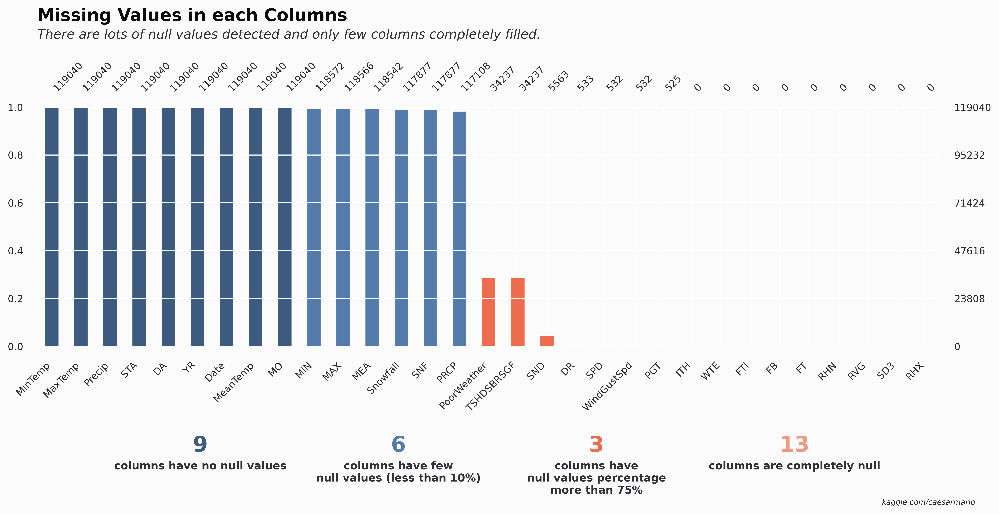

In [ ]:
# --- Missing No Data Frame ---
df_null = df.isnull().sum()
df_null = pd.DataFrame({'Column Name':df_null.index, 'Total':df_null.values})

# --- Other Settings ---
color_mso = ['#3D5A80', '#3D5A80', '#3D5A80', '#3D5A80', '#3D5A80', '#3D5A80', '#3D5A80', '#3D5A80', '#3D5A80', '#557BAD', '#557BAD', '#557BAD', '#557BAD', '#557BAD', '#557BAD', '#EE6C4D', '#EE6C4D', '#EE6C4D']
not_null = 9
few_null = 6
nearly_null = 3
complete_null = 13

# --- Plot Missing Values ---
mso.bar(df, fontsize=9, color=color_mso, figsize=(15, 4), sort='descending', labels=True)

# --- Plot Settings ---
plt.suptitle('Missing Values in each Columns', fontweight='heavy', x=0.125, y=1.2, ha='left',fontsize=16, fontfamily='sans-serif', color='#100C07')
plt.title('There are lots of null values detected and only few columns completely filled.', style='italic', fontsize=12, color='#303035', loc='left', pad=20)
plt.text(5.1, -0.46, not_null, color='#3D5A80', fontsize=20, ha='center', weight='bold', va='bottom')
plt.text(5.1, -0.48, 'columns have no null values', color='#303035', fontsize=10, ha='center', va='top', weight='bold')
plt.text(11.9, -0.46, few_null, color='#557BAD', fontsize=20, ha='center', weight='bold', va='bottom')
plt.text(11.9, -0.48, 'columns have few\nnull values (less than 10%)', color='#303035', fontsize=10, ha='center', va='top', weight='bold')
plt.text(18.7, -0.46, nearly_null, color='#EE6C4D', fontsize=20, ha='center', weight='bold', va='bottom')
plt.text(18.7, -0.48, 'columns have\nnull values percentage\nmore than 75%', color='#303035', fontsize=10, ha='center', va='top', weight='bold')
plt.text(25.5, -0.46, complete_null, color='#F39780', fontsize=20, ha='center', weight='bold', va='bottom')
plt.text(25.5, -0.48, 'columns are completely null', color='#303035', fontsize=10, ha='center', va='top', weight='bold')
plt.gcf().text(0.85, -0.4, 'kaggle.com/caesarmario', style='italic', fontsize=7)
plt.grid(axis='both', alpha=0);

<div class="explain-box">
    Since most of the columns <b>have many null values</b>, and this notebook <b>only uses a few columns</b>, <mark><b>the unused columns will be dropped</b></mark>.
</div>
<!-- Hello world 👋. Thank you so much for downloading/forking my codes/works. If you like my works, please support me by giving upvotes and comments on my Kaggle profile (https://www.kaggle.com/caesarmario/). Thank you so much and have a great day 😆👍. More about me: https://linktr.ee/caesarmario_ -->

In [ ]:
# --- Subset Columns ---
df = df[['MaxTemp', 'MinTemp']]

# --- Display New Dataframe ---
print(clr.start+'.: New Dataframe :.'+clr.end)
print(clr.clr+'*'*20+clr.end)
df.head().style.background_gradient(cmap='Oranges').hide(axis='index')

.: New Dataframe :.
********************


MaxTemp,MinTemp
25.555556,22.222222
28.888889,21.666667
26.111111,22.222222
26.666667,22.222222
26.666667,21.666667


# <div class="header1">4. | Data Exploration 🔍</div>
<div class="explain-box">
    This section will focused on <b>data exploration on the dataset</b> before implementing linear regression.
</div>

In [ ]:
# --- Dataset Report ---
ProfileReport(df, title='WW2 Dataset Report', minimal=True, progress_bar=False, samples=None, correlations=None, explorative=True, notebook={'iframe':{'height': '650px'}}, html={'style':{'primary_color': '#45658F'}}, missing_diagrams={'heatmap': False, 'dendrogram': False}).to_notebook_iframe()

100%|██████████| 31/31 [00:01<00:00, 28.24it/s]


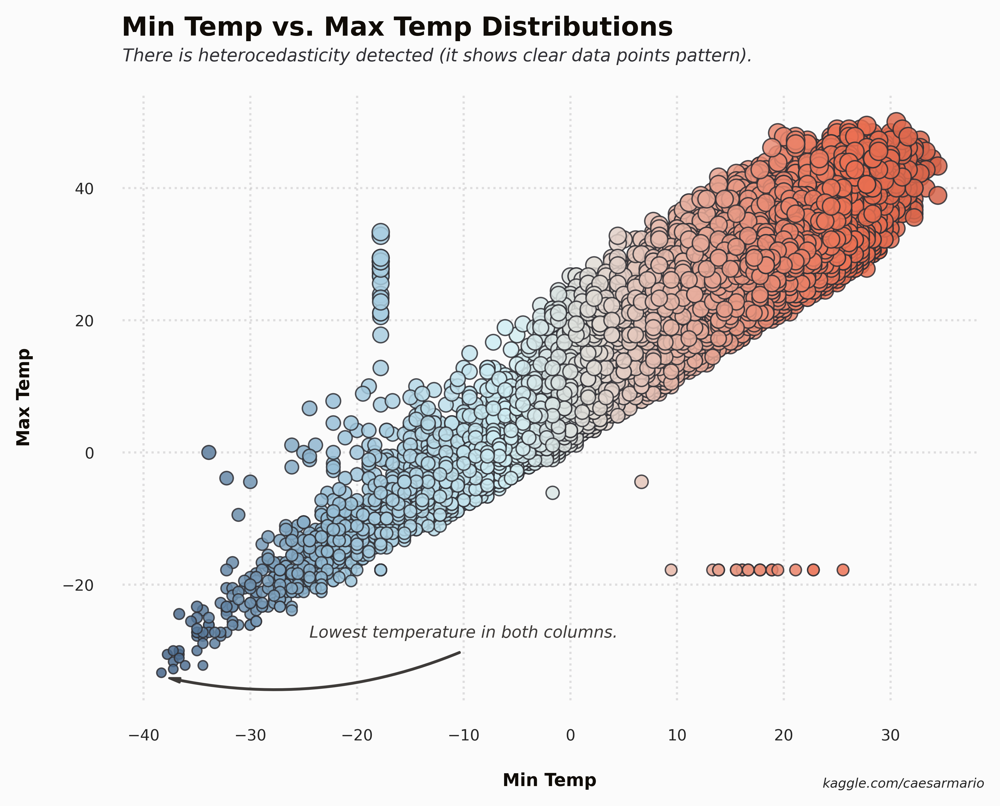

In [ ]:
# --- Arrow Settings ---
style = 'Simple, tail_width=0.3, head_width=2, head_length=5'
kw = dict(arrowstyle=style, color='#3E3B39')
arrow = patches.FancyArrowPatch((-10, -30), (-38, -34), connectionstyle='arc3, rad=-0.16', **kw)
color_grad = ['#47668A', '#7194B2', '#99C1D9', '#B6D9E7', '#D1EFF5', '#E2DDD7', '#E7B5A6', '#EA8E77', '#ED7153', '#D7654B']
color_map = LinearSegmentedColormap.from_list('color_map', colors=color_grad, N=256)

# --- Display Scatter Plot ---
plt.figure(figsize=(7, 5))
sns.scatterplot(data=df, x='MinTemp', y='MaxTemp', alpha=0.85, size='MaxTemp', hue='MinTemp', palette=color_map, legend=False, linewidth=0.65, edgecolor='#303035')
plt.suptitle('Min Temp vs. Max Temp Distributions', fontweight='heavy', x=0.124, y=0.98, ha='left', fontsize=12, color='#100C07')
plt.title('There is heterocedasticity detected (it shows clear data points pattern).\n', style='italic', fontsize=8, loc='left', color='#303035')
plt.xlabel('\nMin Temp', fontweight='bold', fontsize=8, fontfamily='sans-serif', color='#100C07')
plt.ylabel('Max Temp\n', fontweight='bold', fontsize=8, fontfamily='sans-serif', color='#100C07')
plt.xticks(fontsize=7)
plt.yticks(fontsize=7)
plt.gca().add_patch(arrow)
plt.text(x=-10, y=-28, s='Lowest temperature in both columns.', color='#3E3B39', size=7.5, style='italic', ha='center')
plt.grid(axis='y', which='major', alpha=0.3, color='#9B9A9C', linestyle='dotted', zorder=1)
plt.grid(axis='x', which='major', alpha=0.3, color='#9B9A9C', linestyle='dotted', zorder=1)
plt.gcf().text(0.76, -0.001, 'kaggle.com/caesarmario', style='italic', fontsize=6)
ax=plt.gca()
for spine in ax.spines.values():
    spine.set_color('None')
plt.show();

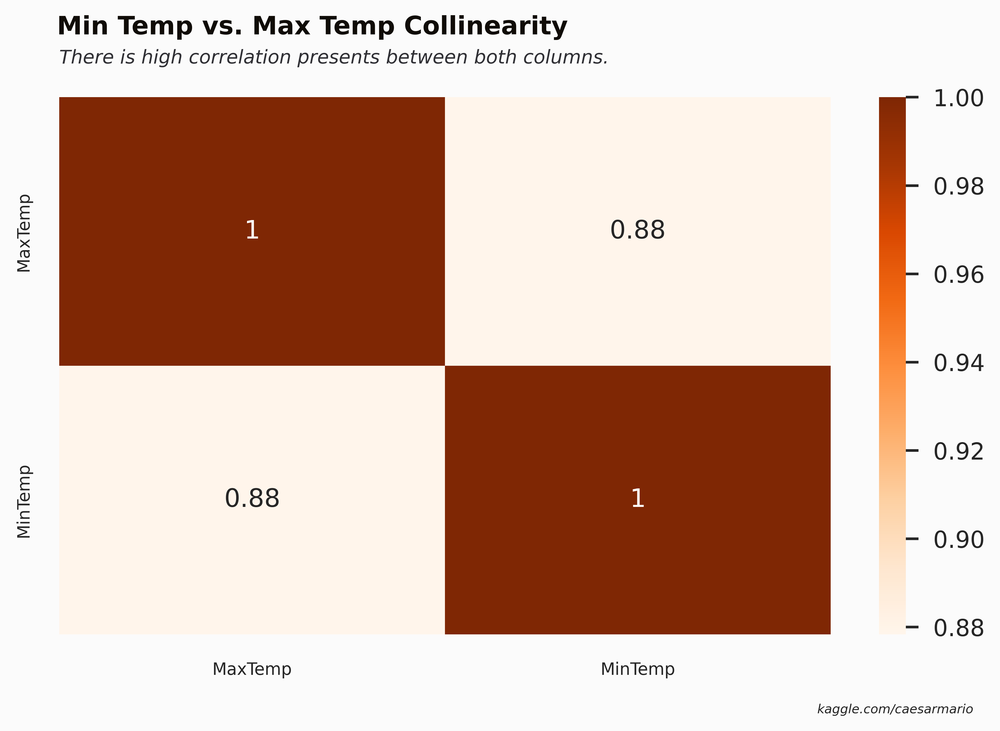

In [ ]:
# --- Display Corr. Map (Heatmap) ----
plt.figure(figsize=(7, 5))
sns.heatmap(df.corr(), annot=True, cmap='Oranges')
plt.suptitle('Min Temp vs. Max Temp Collinearity', fontweight='heavy', x=0.065, y=0.95, ha='left',  fontsize=12, color='#100C07')
plt.title('There is high correlation presents between both columns.\n',  style='italic', fontsize=9, loc='left', color='#303035')
plt.xticks(fontsize=8)
plt.yticks(fontsize=8)
plt.gcf().text(0.78, 0.03, 'kaggle.com/caesarmario', style='italic', fontsize=6)
plt.tight_layout(rect=[0, 0.04, 1, 1.01])

<div class="explain-box">
    From <b>dataset report</b> and <b>correlation matrix</b> above, it can be <mark><b>concluded</b></mark> that:
    <blockquote style="color: #000000;">
        <ul>
            <li>The report above shows that <mark><b>both columns are highly left-skewed</b></mark> (as evidenced by the <b>skewness value</b> and the <b>comparison of the mean and median values</b>). In addition, the <mark><b>two columns above are leptokurtic</b></mark> (evidenced from the <b>kurtosis value</b>, which is <b>more than 3</b>).</li>
            <li>In the <b>histogram distribution</b> of both columns, it can be seen that there are <mark><b>long tails (outliers)</b></mark> visible on <mark><b>the left side</b></mark>.</li>
            <li>The <b>standard deviation values</b> for the two columns are <b>smaller than the mean</b>, so it can be concluded that the <mark><b>two columns lack variation</b></mark>.</li>
            <li>When the two columns are <b>compared</b>, the <mark><b>MinTemp minimum value is lower (cooler)</b></mark> than the MaxTemp. On the other hand, the <mark><b>MaxTemp column's maximum value is higher (hotter)</b></mark> than MinTemp's.</li>
            <li>Based on the <b>MAD values</b>, it can be seen that the <mark><b>difference between temperature values for the both columns is minimal</b></mark> (2.7 Celsius).</li>
            <li>The scatter plot clearly shows <mark><b>heterocedasticity</b></mark>, since the Min Temp values increases, the Max Temp also increases until form a cone shape. In addition, the heatmap shows that there is <mark><b>significant correlation</b></mark> between Min Temp and Max Temp column.</li>
        </ul>
    </blockquote>
</div>

# <div class="header1">5. | Datasets Pre-processing 🧹</div>
<div class="explain-box">
    The data will be split into a ratio of <mark><b>80:20</b></mark> (80% training and 20% testing). However, before splitting the data will be <mark><b>separated into two columns</b></mark> (X and y), with <b>MaxTemp is the dependent variable</b> and <b>MinTemp is the independent variable</b>.
</div>

In [ ]:
# --- Features Separating ---
X = df['MinTemp']
y = df['MaxTemp']

# --- Splitting ---
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=73)

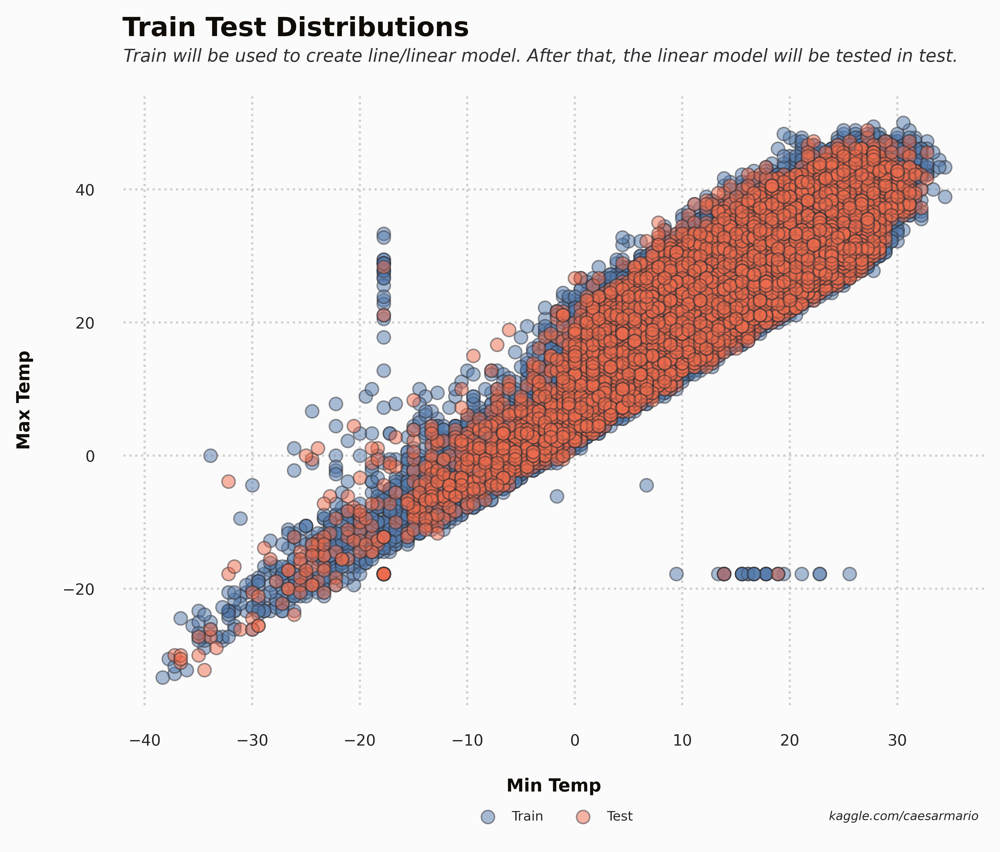

In [ ]:
# --- Display Dataset Split ---
plt.figure(figsize=(7, 5))
plt.scatter(X_train, y_train, label='Training Data', color='#557BAD', alpha=0.5, linewidth=0.65, edgecolor='#303035')
plt.scatter(X_test, y_test, label='Testing Data', color='#EE6C4D', alpha=0.5, linewidth=0.65, edgecolor='#303035')
plt.suptitle('Train Test Distributions', fontweight='heavy', x=0.124, y=0.98, ha='left', fontsize=12, color='#100C07')
plt.title('Train will be used to create line/linear model. After that, the linear model will be tested in test.\n', style='italic', fontsize=8, loc='left', color='#303035')
plt.xlabel('\nMin Temp', fontweight='bold', fontsize=8, fontfamily='sans-serif', color='#100C07')
plt.ylabel('Max Temp\n', fontweight='bold', fontsize=8, fontfamily='sans-serif', color='#100C07')
plt.xticks(fontsize=7)
plt.yticks(fontsize=7)
plt.grid(axis='y', which='major', alpha=0.3, color='#6D6A6A', linestyle='dotted', zorder=1)
plt.grid(axis='x', which='major', alpha=0.3, color='#6D6A6A', linestyle='dotted', zorder=1)
plt.legend(['Train', 'Test'], fontsize=6, loc='upper center', frameon=False, ncol=2, borderpad=1, bbox_to_anchor=(0.5, -0.14))
plt.gcf().text(0.76, -0.035, 'kaggle.com/caesarmario', style='italic', fontsize=5.5)
ax=plt.gca()
for spine in ax.spines.values():
    spine.set_color('None')
plt.show();

# <div class="header1">6. | Linear Regression Theory 🧐</div>
<div class="explain-box">
    This section will first explain <mark><b>what linear regression is, along with its assumptions and evaluation metrics</b></mark>. Furthermore, based on the theories described, <mark><b>this section will implement linear regression and evaluate the results obtained</b></mark>.
</div>

## <div class="header3">What is Linear Regression ❓</div>
<div class="explain-box">
    <blockquote style="color: #000000;">
    The supervised machine learning approach known as <mark><b>"linear regression"</b></mark> identifies the <b>linear connection between the dependent and independent variables</b> by determining which <b>linear line</b> between the independent and dependent variables <b>fits the data the best</b>. The primary <mark><b>goal</b></mark> of a linear regression model is to <b>identify the best-fitting linear line and the ideal intercept and coefficient values that minimize error</b>. The objective is to <b>lessen this disparity</b>, which represents the gap between the actual value and the predicted value.<br><br>
    <span style="font-size: 16px;">▶ Formula:</span><br>
     <center>$$ y = b_o + b_1x $$</center>
     with:
      <ul>
        <li>$ x $ = independent variable</li>
        <li>$ y $ = dependent variable</li>
        <li>$ b_o $ = intercept</li>
        <li>$ b_1 $ = coefficient or slope</li>
      </ul>
    <center>
    <img src="https://cdn.analyticsvidhya.com/wp-content/uploads/2021/05/2.3.png" alt="LR Diagram" width="40%"><br>
    <i>🖼 Linear Regression Diagram by <a href="https://www.analyticsvidhya.com/blog/2021/05/all-you-need-to-know-about-your-first-machine-learning-model-linear-regression/">Deepanshi</a></i>
    </center>
    </blockquote>
</div>
<!-- Hello world 👋. Thank you so much for downloading/forking my codes/works. If you like my works, please support me by giving upvotes and comments on my Kaggle profile (https://www.kaggle.com/caesarmario/). Thank you so much and have a great day 😆👍. More about me: https://linktr.ee/caesarmario_ -->

## <div class="header3">Linear Regression Assumptions 🔍</div>
<div class="explain-box">
    <blockquote style="color: #000000;">
        <ol>
            <li><mark><b>Linearity</b></mark>&emsp;: The dependent variable $ y $ should have a <b>linear relationship</b> with the independent variables. A <b>scatter plot</b> between the two variables will help to assure this assumption.<br></li>
            <li><mark><b>Normality</b></mark>&emsp;: Both the $ x $ and $ y $ variables <b>should to follow a normal distribution</b>.</li>
            <li><mark><b>Homoscedasticity</b></mark>&emsp;: The spread of the residuals, or the variance of the error terms, <b>ought to be constant for all values of $ x $</b>.</li>
            <li><mark><b>Independence/No Multicollinearity</b></mark>&emsp;: There should be <b>no connection between the variables</b>, which means that they should be independent of one another.</li>
            <li><mark><b>The error terms should be normally distributed</b></mark></li>
            <li><mark><b>No Autocorrelation</b></mark>&emsp;: It is recommended that the <b>error terms remain independent</b>. Using the <b>Durbin-Watson test</b>, autocorrelation can be evaluated.</li>
        </ol>
    </blockquote>
</div>
<!-- Hello world 👋. Thank you so much for downloading/forking my codes/works. If you like my works, please support me by giving upvotes and comments on my Kaggle profile (https://www.kaggle.com/caesarmario/). Thank you so much and have a great day 😆👍. More about me: https://linktr.ee/caesarmario_ -->

## <div class="header3">Linear Regression Evaluation Metrics 📏</div>
<div class="explain-box">
    <blockquote style="color: #000000;">
        In regression analysis, there are some <b>metrics</b> to evaluate the performance of the model. Those metrics are:
        <ul>
            <li><mark><b>R Squared or Coefficient of Determination</b></mark> -- Interpreted as how well the regression model explains observed data,</li>
            <li><mark><b>Mean Absolute Error (MAE)</b></mark> -- Lower values indicates better model,</li>
            <li><mark><b>Mean Squared Error (MSE)</b></mark> -- Better model is indicated by lower values,</li>
            <li><mark><b>Root Mean Squared Error (RMSE)</b></mark> -- Lower values indicates better model.</li>
        </ul>
    </blockquote>
</div>
<!-- Hello world 👋. Thank you so much for downloading/forking my codes/works. If you like my works, please support me by giving upvotes and comments on my Kaggle profile (https://www.kaggle.com/caesarmario/). Thank you so much and have a great day 😆👍. More about me: https://linktr.ee/caesarmario_ -->

## <div class="header2">6.1 | Implementing Linear Regression ⚙️</div>
<div class="explain-box">
    After knowing the linear regression theory, assumptions, and evaluation metrics, the next step is <b>implementing the linear regression model</b>. Implementation will use the <mark><b>shuffle split method</b></mark>, randomly sampling the complete dataset on each iteration to produce a training and test set. Then, <b>evaluation metrics</b> will be used to <mark><b>evaluate the model performance</b></mark>.
</div>
<!-- Hello world 👋. Thank you so much for downloading/forking my codes/works. If you like my works, please support me by giving upvotes and comments on my Kaggle profile (https://www.kaggle.com/caesarmario/). Thank you so much and have a great day 😆👍. More about me: https://linktr.ee/caesarmario_ -->

In [ ]:
# --- Define Shuffle Split ---
cv = ShuffleSplit(n_splits=10, test_size=0.2, random_state=4)

# --- Set & Fit Linear Regression Model ---
lr = LinearRegression()
model_LR = lr.fit(X_train.values.reshape(-1, 1), y_train)

# --- Applying Cross Validation w/ Shuffle Split ---
cv_score = cross_val_score(lr, X_train.values.reshape(-1, 1), y_train, cv=cv, n_jobs=-1)

# --- Perform Prediction ---
y_pred = cross_val_predict(model_LR, X_test.values.reshape(-1, 1), y_test, cv=10)

In [ ]:
# --- Cross Validation Scores ---
print(clr.start+'.: Cross Validation Result :.'+clr.end)
print(clr.clr+'*'*30+clr.end)
print(f'\t>> Average Score: '+clr.start+'{:.4f}'.format(cv_score.mean())+clr.end)
print(f'\t>> Standard Deviation: '+clr.start+'{:.4f}'.format(cv_score.std())+clr.end)

# --- LR Metrics ---
print('\n'+clr.start+'.: Evaluation Metrics :.'+clr.end)
print(clr.clr+'*'*25+clr.end)
print(f'\t>> MAE: '+clr.start+'{:.6f}'.format(metrics.mean_absolute_error(y_test, y_pred))+clr.end)
print(f'\t>> MSE: '+clr.start+'{:.6f}'.format(metrics.mean_squared_error(y_test, y_pred))+clr.end)
print(f'\t>> RMSE: '+clr.start+'{:.6f}'.format(np.sqrt(metrics.mean_squared_error(y_test, y_pred)))+clr.end)
print(f'\t>> R Squared: '+clr.start+'{:.6f}'.format(metrics.r2_score(y_test, y_pred))+clr.end)

# --- Intercept and Coefficients ---
print('\n'+clr.start+'.: Intercept & Coefficients :.'+clr.end)
print(clr.clr+'*'*31+clr.end)
print(f'\t>> Intercept (b0): '+clr.start+'{:.4f}'.format(model_LR.intercept_)+clr.end)
print(f'\t>> Coefficients (b1): '+clr.start+'{:.4f}'.format(model_LR.coef_[0])+clr.end)

.: Cross Validation Result :.
******************************
	>> Average Score: 0.7710
	>> Standard Deviation: 0.0031

.: Evaluation Metrics :.
*************************
	>> MAE: 3.161868
	>> MSE: 16.845124
	>> RMSE: 4.104281
	>> R Squared: 0.770723

.: Intercept & Coefficients :.
*******************************
	>> Intercept (b0): 10.6635
	>> Coefficients (b1): 0.9205


<div class="explain-box">
    Based on the results above, <b>it can be concluded that</b>:
    <blockquote style="color: #000000;">
        <ul>
            <li>From the results of the <b>average CV score</b>, it can be said that the <mark><b>model's performance is good</b></mark>. In addition, from <b>CV standard deviation value</b>, it can be concluded that <mark><b>the model has very minimum variance</b></mark> between each CV scores.</li>
            <li>From evaluation metrics score, it can be seen that <b>RMSE and MAE value is close to 0</b>. In addition, the <b>R squared value</b> also reveals that <b>77% of the variability observed in the target variable is explained by the regression model</b>. Based on those results, it can be concluded that <mark><b>the model has good performance</b></mark>.</li>
            <li>Based on the intercept and coefficients result, the <mark><b>linear regression formula</b></mark> will be:</li>
            <center><b>$$ .: y = 10.6635 + 0.9205x :. $$</b></center>
            with:
                <ul>
                    <li>$ x $ = independent variable (<b>MinTemp</b>)</li>
                    <li>$ y $ = dependent variable (<b>MaxTemp</b>)</li>
                </ul>
        </ul>
    </blockquote>
</div>
<!-- Hello world 👋. Thank you so much for downloading/forking my codes/works. If you like my works, please support me by giving upvotes and comments on my Kaggle profile (https://www.kaggle.com/caesarmario/). Thank you so much and have a great day 😆👍. More about me: https://linktr.ee/caesarmario_ -->

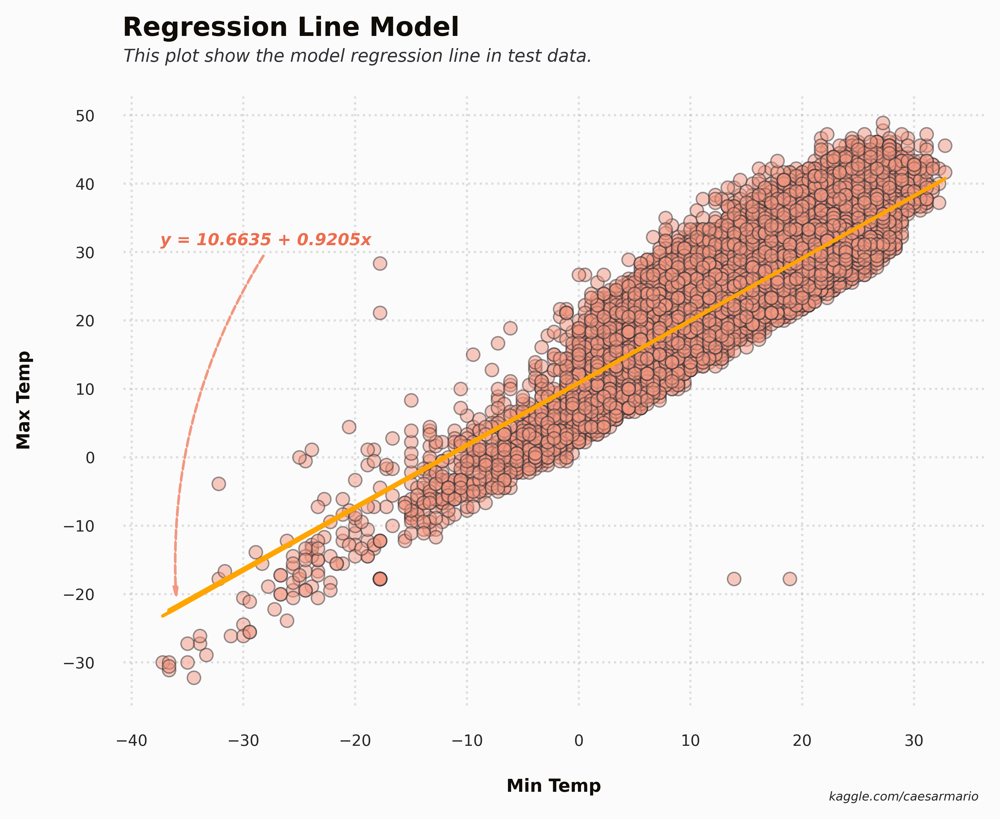

In [ ]:
# --- Arrow Settings ---
style = 'Simple, tail_width=0.2, head_width=2, head_length=5'
kw = dict(arrowstyle=style, color='#F39780')
arrow = patches.FancyArrowPatch((-28, 30), (-36, -21), ls='dashed', connectionstyle='arc3, rad=0.16', **kw)

# --- Model Regression Line ---
plt.figure(figsize=(7, 5))
plt.scatter(X_test, y_test, label='Actual Data', color='#F39780', alpha=0.5, linewidth=0.65, edgecolor='#303035')
plt.plot(X_test, y_pred, label='Regression Line', color='orange')
plt.suptitle('Regression Line Model', fontweight='heavy', x=0.124, y=0.98, ha='left', fontsize=12, color='#100C07')
plt.title('This plot show the model regression line in test data.\n', style='italic', fontsize=8, loc='left', color='#303035')
plt.xlabel('\nMin Temp', fontweight='bold', fontsize=8, fontfamily='sans-serif', color='#100C07')
plt.ylabel('Max Temp\n', fontweight='bold', fontsize=8, fontfamily='sans-serif', color='#100C07')
plt.xticks(fontsize=7)
plt.yticks(fontsize=7)
plt.grid(axis='y', which='major', alpha=0.3, color='#9B9A9C', linestyle='dotted', zorder=1)
plt.grid(axis='x', which='major', alpha=0.3, color='#9B9A9C', linestyle='dotted', zorder=1)
plt.gca().add_patch(arrow)
plt.text(x=-28, y=31, s='y = 10.6635 + 0.9205x', color='#EE6C4D', size=7.5, weight='bold', style='italic', ha='center')
plt.gcf().text(0.76, -0.01, 'kaggle.com/caesarmario', style='italic', fontsize=5.5)
ax=plt.gca()
for spine in ax.spines.values():
    spine.set_color('None')
plt.show();

<div class="explain-box">
    The following plot will <b>compare the actual and predicted temperatures</b>. Due to large amount of data, the following plot will use the <b>first 15 data as samples</b> to compare actual and predicted temperatures.
</div>
<!-- Hello world 👋. Thank you so much for downloading/forking my codes/works. If you like my works, please support me by giving upvotes and comments on my Kaggle profile (https://www.kaggle.com/caesarmario/). Thank you so much and have a great day 😆👍. More about me: https://linktr.ee/caesarmario_ -->

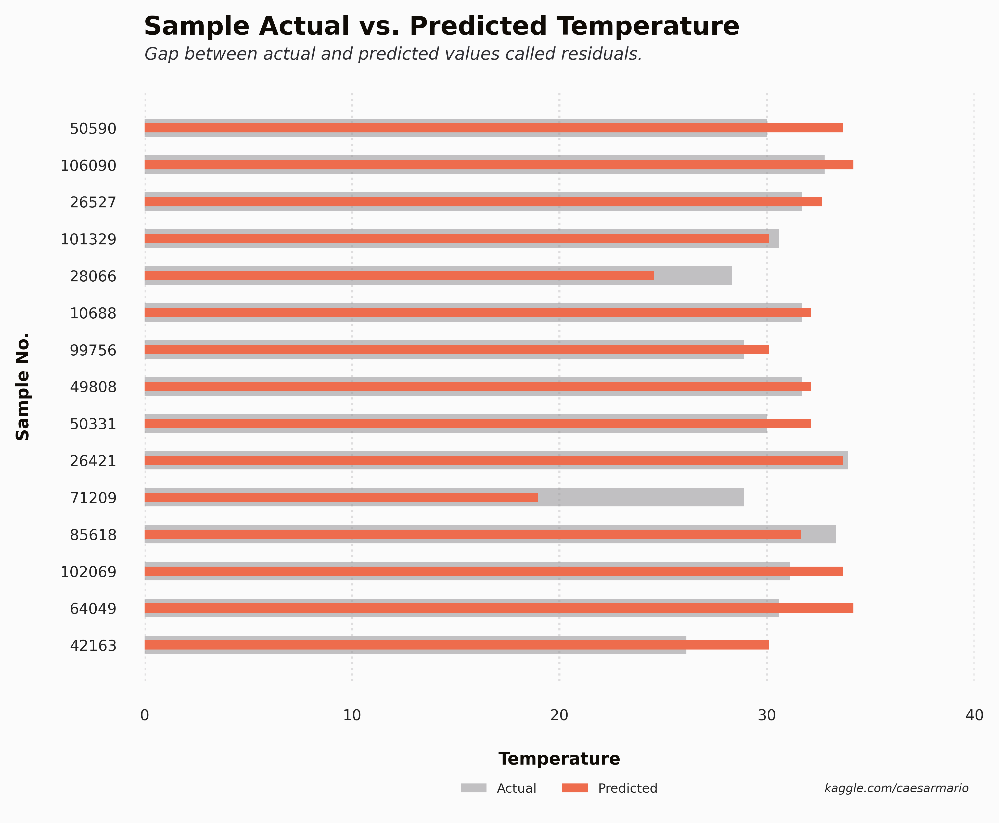

In [ ]:
# --- Actual vs. Prediction Data Frame ---
df_pred = pd.DataFrame({'Actual Temp.': y_test, 'Predicted Temp.': y_pred})
df_pred_sample = df_pred.head(15).round(2)
df_pred_index = df_pred_sample.index.astype(str)

# --- Bar Plot Settings ---
x_ticks = []
for i in np.arange(0, 50, 10):
    x_ticks.append(i)

# --- Bar Plot ---
fig = plt.figure(figsize=(7, 5))
bar1 = plt.barh(df_pred_index, df_pred_sample['Actual Temp.'], zorder=3, color='#9B9A9C', edgecolor='none', alpha=0.6, height=0.5)
bar2 = plt.barh(df_pred_index, df_pred_sample['Predicted Temp.'], zorder=3, color='#EE6C4D', edgecolor='none', height=0.25)
plt.suptitle('Sample Actual vs. Predicted Temperature', fontweight='heavy', x=0.124, y=0.98, ha='left', fontsize=12, color='#100C07')
plt.title('Gap between actual and predicted values called residuals.\n', style='italic', fontsize=8, loc='left', color='#303035')
plt.xlabel('\nTemperature', fontweight='bold', fontsize=8, fontfamily='sans-serif', color='#100C07')
plt.ylabel('Sample No.\n', fontweight='bold', fontsize=8, fontfamily='sans-serif', color='#100C07')
plt.xticks(fontsize=7, ticks=x_ticks)
plt.yticks(fontsize=7)
plt.grid(axis='y', alpha=0)
plt.grid(axis='x', which='major', alpha=0.3, color='#9B9A9C', linestyle='dotted', zorder=1)
plt.legend(['Actual', 'Predicted'], fontsize=6, loc='upper center', frameon=False, ncol=2, borderpad=1, bbox_to_anchor=(0.5, -0.14))
plt.gcf().text(0.76, -0.035, 'kaggle.com/caesarmario', style='italic', fontsize=5.5)
ax=plt.gca()
for spine in ax.spines.values():
    spine.set_color('None')
plt.show();

## <div class="header2">6.2 | Evaluating Assumptions 🔍</div>
## <div class="header3">6.2.1 | Linearity Assumption</div>
<!-- Hello world 👋. Thank you so much for downloading/forking my codes/works. If you like my works, please support me by giving upvotes and comments on my Kaggle profile (https://www.kaggle.com/caesarmario/). Thank you so much and have a great day 😆👍. More about me: https://linktr.ee/caesarmario_ -->

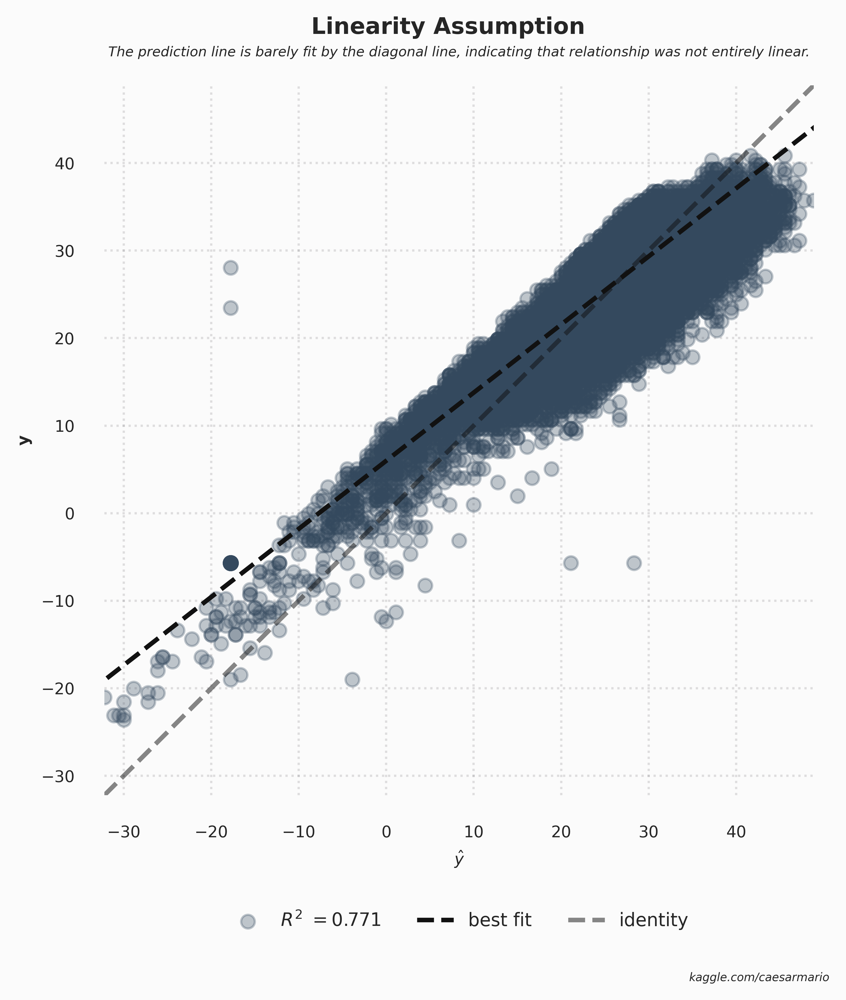

In [ ]:
# --- Figures Settings ---
set_palette('flatui')
title=dict(fontsize=6, style='italic')
grid_style=dict(alpha=0.3, color='#9B9A9C', linestyle='dotted', zorder=1)
xy_label=dict(fontsize=7, fontweight='bold')

# --- Plot Prediction Error ---
fig, ax = plt.subplots(figsize = (7, 6))
pred_error = PredictionError(model_LR, alpha=0.3)
pred_error.fit(X_train.values.reshape(-1, 1), y_train)
pred_error.score(X_test.values.reshape(-1, 1), y_test)
pred_error.finalize()
pred_error.ax.set_title('The prediction line is barely fit by the diagonal line, indicating that relationship was not entirely linear.\n', **title)
pred_error.ax.tick_params(labelsize=7)
pred_error.ax.set_xlabel(xlabel=r'$\^y$', **xy_label)
pred_error.ax.set_ylabel(ylabel='y', **xy_label)
pred_error.ax.grid(axis='y', **grid_style)
pred_error.ax.grid(axis='x', **grid_style)
for text in pred_error.ax.legend_.texts:
     text.set_fontsize(8)
for spine in pred_error.ax.spines.values():
    spine.set_color('None')
pred_error.ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.1), borderpad=2, ncol=3, frameon=False, fontsize=8)
pred_error.fig.tight_layout()
pred_error.fig.show()
plt.suptitle('Linearity Assumption', fontsize=10, fontweight='bold', y=1, ha='center')
plt.gcf().text(0.71, 0.02, 'kaggle.com/caesarmario', style='italic', fontsize=5)
plt.show();

<div class="explain-box">
    The scatter plot above shows that <mark><b>it is not a perfect linear relationship</b></mark> since the predicted line barely fits the diagonal line. The predictions are skewed towards lower values (between -10 and 0) and especially towards higher values (above 20). It is advised to <b>apply nonlinear transformations</b> or <b>add polynomial terms to some predictors</b>. If those fail to reflect the relationship between the predictors and the label, <b>consider using more variables</b>.
    <blockquote style="font-size: 18px;">
        <b>. : . <mark class="mark">Linearity assumption not satisfied</mark> . : .</b>
    </blockquote>
</div>
<!-- Hello world 👋. Thank you so much for downloading/forking my codes/works. If you like my works, please support me by giving upvotes and comments on my Kaggle profile (https://www.kaggle.com/caesarmario/). Thank you so much and have a great day 😆👍. More about me: https://linktr.ee/caesarmario_ -->

## <div class="header3">6.2.2 | Normality Assumption</div>
<!-- Hello world 👋. Thank you so much for downloading/forking my codes/works. If you like my works, please support me by giving upvotes and comments on my Kaggle profile (https://www.kaggle.com/caesarmario/). Thank you so much and have a great day 😆👍. More about me: https://linktr.ee/caesarmario_ -->

.: Normality Assumption :.
***************************
- The Residuals are not normally distributed, since the p-value is 0.00.

.:. The assumption not satisfied .:.
>> Advised to perform non-linear transformations on variables. <<



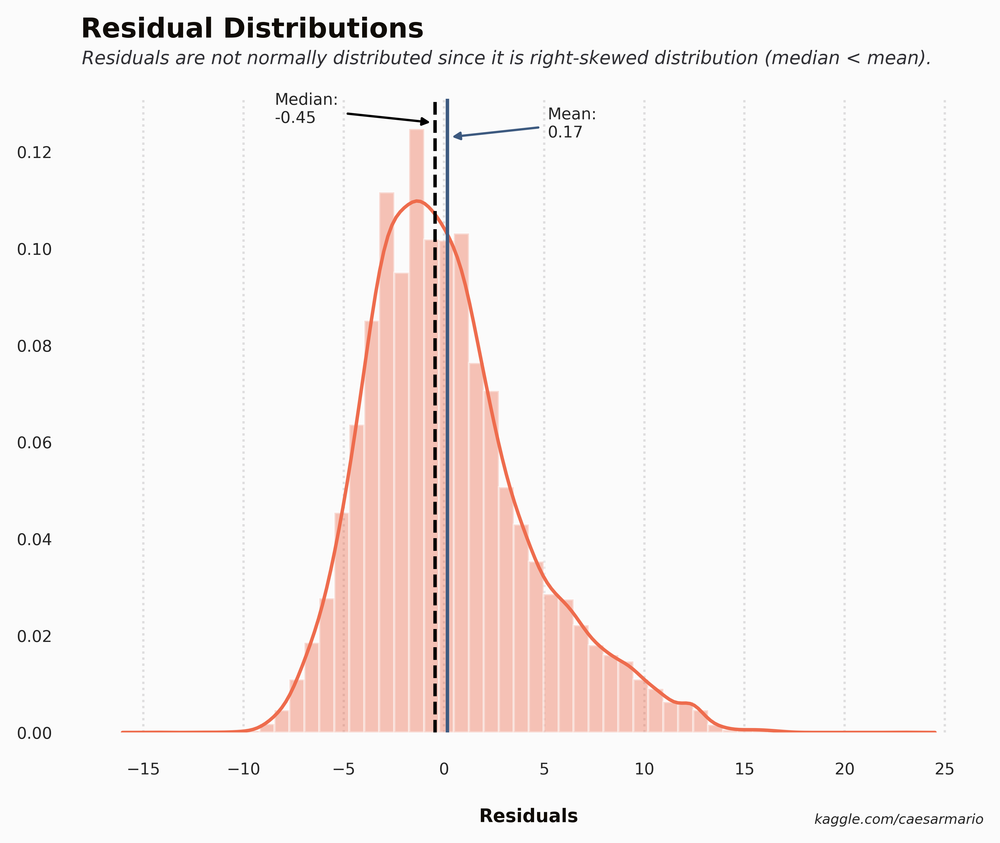

In [ ]:
# --- Calculating Residuals & Others ---
p_value_thresh=0.05
df_pred['Residuals'] = abs(df_pred['Actual Temp.']) - abs(df_pred['Predicted Temp.'])
p_value = normal_ad(df_pred['Residuals'])[1]
resd_mean = df_pred.Residuals.mean()
resd_median = df_pred.Residuals.median()

# --- If-else Function ---
print(clr.start+'.: Normality Assumption :.'+clr.end)
print(clr.clr+'*'*27+clr.end)
if p_value < p_value_thresh:
    print('- The Residuals are '+clr.start+'not normally distributed'+clr.end+', since the p-value is '+clr.start+'{:.2f}'.format(p_value)+clr.end+'.')
    print('\n.:. The '+clr.start+'assumption not satisfied'+clr.end+' .:.')
    print('>> Advised to perform'+clr.start+' non-linear transformations '+clr.end+'on variables. <<\n')
else:
    print('- The Residuals are '+clr.start+'normally distributed'+clr.end+', since the p-value is '+clr.start+'{:.2f}'.format(p_value)+clr.end+'.')
    print('\n.:. The '+clr.start+'assumption satisfied'+clr.end+' .:.\n')

# --- Plot Residual Distributions ---
plt.figure(figsize=(7, 5))
sns.distplot(df_pred['Residuals'], color='#EE6C4D')
plt.suptitle('Residual Distributions', fontweight='heavy', x=0.124, y=0.98, ha='left', fontsize=12, color='#100C07')
plt.title('Residuals are not normally distributed since it is right-skewed distribution (median < mean).\n', style='italic', fontsize=8, loc='left', color='#303035')
plt.xlabel('\nResiduals', fontweight='bold', fontsize=8, fontfamily='sans-serif', color='#100C07')
plt.ylabel('')
plt.axvline(x=resd_mean, color='#3D5A80')
plt.axvline(x=resd_median, linestyle='--', color='black')
plt.annotate("Mean:\n{:.2f}".format(resd_mean), fontsize=7, xy=(resd_mean, 0.123), xytext=(resd_mean+5, 0.123), arrowprops={"arrowstyle":"-|>", "color":"#3D5A80"})
plt.annotate("Median:\n{:.2f}".format(resd_median), fontsize=7, xy=(resd_median, 0.126), xytext=(resd_median-8, 0.126), arrowprops={"arrowstyle":"-|>", "color":"black"})
plt.xticks(fontsize=7)
plt.yticks(fontsize=7)
plt.grid(axis='x', which='major', alpha=0.3, color='#9B9A9C', linestyle='dotted', zorder=1)
plt.grid(axis='y', alpha=0, zorder=2)
plt.gcf().text(0.76, -0.001, 'kaggle.com/caesarmario', style='italic', fontsize=6)
ax=plt.gca()
for spine in ax.spines.values():
    spine.set_color('None')
plt.show();

<div class="explain-box">
    <mark><b>The distribution is right-skewed</b></mark> since the median value is smaller than the mean value. In addition, <mark><b>the p-value distribution shows that it is smaller than 0.05</b></mark>, which indicates that the distribution is not normal, which <b>may affect the confidence interval</b>. It is <b>suggested to perform non-linear transformations</b> on variables.
    <blockquote style="font-size: 18px;">
        <b>. : . <mark class="mark">Normality assumption not satisfied</mark> . : .</b>
    </blockquote>
</div>
<!-- Hello world 👋. Thank you so much for downloading/forking my codes/works. If you like my works, please support me by giving upvotes and comments on my Kaggle profile (https://www.kaggle.com/caesarmario/). Thank you so much and have a great day 😆👍. More about me: https://linktr.ee/caesarmario_ -->

## <div class="header3">6.2.3 | Multicolinearity Assumption</div>
<!-- Hello world 👋. Thank you so much for downloading/forking my codes/works. If you like my works, please support me by giving upvotes and comments on my Kaggle profile (https://www.kaggle.com/caesarmario/). Thank you so much and have a great day 😆👍. More about me: https://linktr.ee/caesarmario_ -->

In [ ]:
# --- Multicolinearity Test ---
print(clr.start+'.: Multicolinearity Assumption :.'+clr.end)
print(clr.clr+'*'*34+clr.end)
df_X = pd.DataFrame({'X':X.values})
df_X.corr().style.background_gradient(cmap='Oranges_r')

.: Multicolinearity Assumption :.
**********************************


,X
X,1.000000


<div class="explain-box">
    <mark><b>Multicollinearity occurs since the observation data only contains two columns</b></mark>. However, if multicollinearity happens in more than 2 columns data, this problem can be fixed by <b>removing other predictors with a high variance inflation factor (VIF) or performing dimensionality reduction</b>.
    <blockquote style="font-size: 18px;">
        <b>. : . <mark class="mark">Multicollinearity assumption not satisfied</mark> . : .</b>
    </blockquote>
</div>
<!-- Hello world 👋. Thank you so much for downloading/forking my codes/works. If you like my works, please support me by giving upvotes and comments on my Kaggle profile (https://www.kaggle.com/caesarmario/). Thank you so much and have a great day 😆👍. More about me: https://linktr.ee/caesarmario_ -->

## <div class="header3">6.2.4 | Autocorrelation Assumption</div>
<div class="explain-box">
    The autocorrelation test will be used <mark><b>Durbin-Watson test</b></mark> to <b>determine whether a positive or negative correlation is present</b>. The following is the <b>hypothesis of the Durbin-Watson test</b>.
    <blockquote style="color: #000000;">
      <ul>
          <li><b>H<sub>0</sub></b>: There is <mark><b>little/no autocorrelation detected</b></mark>.</li>
          <li><b>H<sub>1</sub></b>: There is <mark><b>positive/negative autocorrelation detected</b></mark>.</li>
      </ul>
    </blockquote>
    <b>Criteria:</b>
    <blockquote style="color: #000000;">
      <ul>
          <li>If the <b>Durbin-Watson test value is between 1.5 and 2.5</b>, <mark><b>accept H<sub>0</sub></b></mark>.</li>
      </ul>
    </blockquote>
</div>
<!-- Hello world 👋. Thank you so much for downloading/forking my codes/works. If you like my works, please support me by giving upvotes and comments on my Kaggle profile (https://www.kaggle.com/caesarmario/). Thank you so much and have a great day 😆👍. More about me: https://linktr.ee/caesarmario_ -->

In [ ]:
# --- Durbin-Watson Test ---
print(clr.start+'.: Durbin-Watson Test :.'+clr.end)
print(clr.clr+'*'*25+clr.end)
durbinWatson = durbin_watson(df_pred['Residuals'])
print(f'>> Result: '+clr.start+'{:.4f}'.format(durbinWatson)+clr.end)

# --- If-else Function ---
if durbinWatson < 1.5:
    print('- It can be concluded that'+clr.start+' there is positive autocorrleation'+clr.end+', since'+clr.start+' the value of Durbin-Watson test is < 1.5'+clr.end+'.')
    print('\n.:. The '+clr.start+'assumption not satisfied'+clr.end+' .:.')
elif durbinWatson > 2.5:
    print('- It can be concluded that'+clr.start+' there is negative autocorrleation'+clr.end+', since'+clr.start+' the value of Durbin-Watson test is > 2.5'+clr.end+'.')
    print('\n.:. The '+clr.start+'assumption not satisfied'+clr.end+' .:.')
else:
    print('- It can be concluded that'+clr.start+' there is little to no autocorrelation'+clr.end+', since'+clr.start+' the value of Durbin-Watson test is between 1.5 and 2.5'+clr.end+'.')
    print('\n.:. The '+clr.start+'assumption satisfied'+clr.end+' .:.')

.: Durbin-Watson Test :.
*************************
>> Result: 1.9902
- It can be concluded that there is little to no autocorrelation, since the value of Durbin-Watson test is between 1.5 and 2.5.

.:. The assumption satisfied .:.


<div class="explain-box">
    As can be seen from the results of the Durbin-Watson test above, it can be concluded that <mark><b>the assumption is satisfied (accept H<sub>0</sub>)</b></mark> since there is <b>little to no autocorrelation detected</b> (the <mark><b>Durbin-Watson value is 1.9902</b></mark>, which is <b>between 1.5 and 2.5</b>).
    <blockquote style="font-size: 18px;">
        <b>. : . <mark>Autocorrelation assumption satisfied</mark> . : .</b>
    </blockquote>
</div>
<!-- Hello world 👋. Thank you so much for downloading/forking my codes/works. If you like my works, please support me by giving upvotes and comments on my Kaggle profile (https://www.kaggle.com/caesarmario/). Thank you so much and have a great day 😆👍. More about me: https://linktr.ee/caesarmario_ -->

## <div class="header3">6.2.5 | Homoscedasticity Assumption</div>
<!-- Hello world 👋. Thank you so much for downloading/forking my codes/works. If you like my works, please support me by giving upvotes and comments on my Kaggle profile (https://www.kaggle.com/caesarmario/). Thank you so much and have a great day 😆👍. More about me: https://linktr.ee/caesarmario_ -->

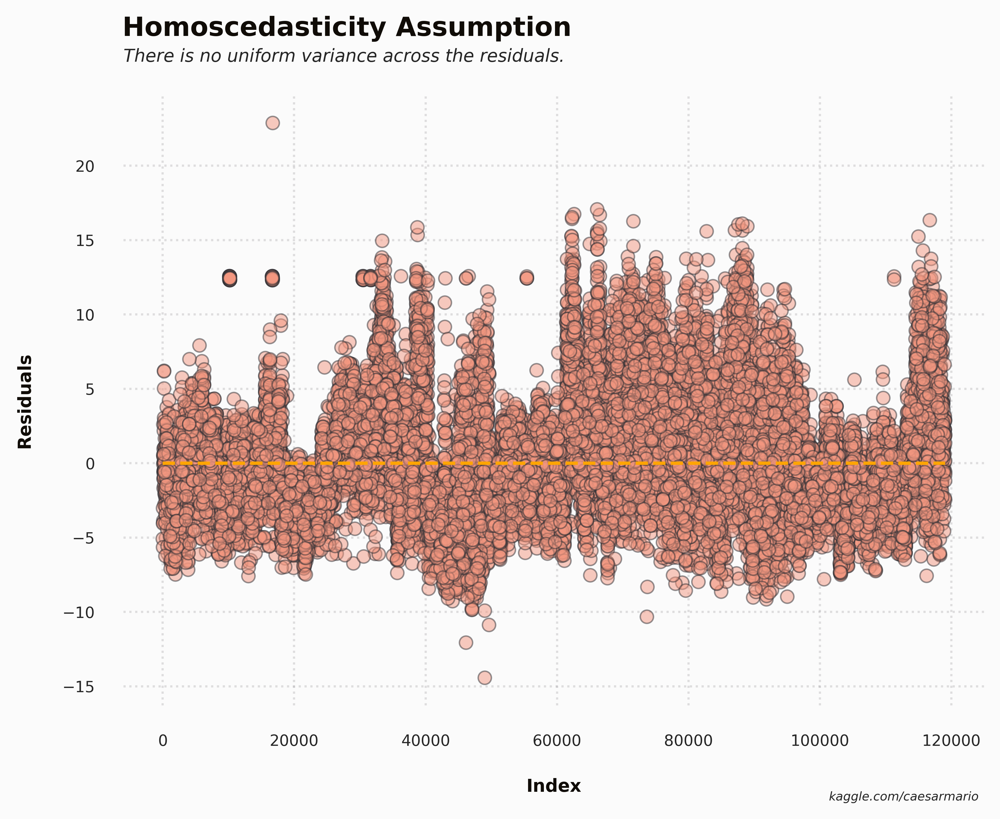

In [ ]:
# --- Homoscedasticity Scatter Plot ---
plt.figure(figsize=(7, 5))
plt.scatter(df_pred.index, df_pred.Residuals, label='Residuals', color='#F39780', alpha=0.5, linewidth=0.65, edgecolor='#303035')
plt.plot(np.repeat(0, df_pred.index.max()), color='orange', linestyle='--')
plt.suptitle('Homoscedasticity Assumption', fontweight='heavy', x=0.124, y=0.98, ha='left', fontsize=12, color='#100C07')
plt.title('There is no uniform variance across the residuals.\n', style='italic', fontsize=8, loc='left')
plt.xlabel('\nIndex', fontweight='bold', fontsize=8, fontfamily='sans-serif', color='#100C07')
plt.ylabel('Residuals\n', fontweight='bold', fontsize=8, fontfamily='sans-serif', color='#100C07')
plt.xticks(fontsize=7)
plt.yticks(fontsize=7)
plt.grid(axis='y', which='major', alpha=0.3, color='#9B9A9C', linestyle='dotted', zorder=1)
plt.grid(axis='x', which='major', alpha=0.3, color='#9B9A9C', linestyle='dotted', zorder=1)
ax=plt.gca()
for spine in ax.spines.values():
    spine.set_color('None')
plt.gcf().text(0.76, -0.01, 'kaggle.com/caesarmario', style='italic', fontsize=5.5)
plt.show();

<div class="explain-box">
    There is <mark><b>no uniform variance across the residuals</b></mark>, which is potentially problematic. This can be solved by either <b>using weighted least squares regression</b> instead of the standard OLS or transforming the dependent or highly skewed variables. A <b>log transformation</b> on the dependent variable is also a good starting point.
    <blockquote style="font-size: 18px;">
        <b>. : . <mark class="mark">Homoscedasticity assumption not satisfied</mark> . : .</b>
    </blockquote>
</div>
<!-- Hello world 👋. Thank you so much for downloading/forking my codes/works. If you like my works, please support me by giving upvotes and comments on my Kaggle profile (https://www.kaggle.com/caesarmario/). Thank you so much and have a great day 😆👍. More about me: https://linktr.ee/caesarmario_ -->

## <div class="header2">6.3 | Conclusions 👀</div>
<div class="explain-box">
    From the results of the implementation of linear regression, model evaluation, and assumptions results, <mark><b>it can be concluded that</b></mark>:
    <blockquote style="color: #000000;">
        <ul>
            <li>The model gets a <mark><b>good average cross-validation score</b></mark> from implementing the linear regression model using the <b>shuffle-split method</b>. Additionally, it is clear from the cross-validation standard deviation number that <b>there is minimal variation between each CV score in the model</b>. The model also has <b>very minimum RMSE and MAE values with a 77% R Squared value</b>.</li>
            <li>However, from the 5 assumptions tested on the model residuals, it can be seen that <mark><b>4 out of 5 assumptions are not satisfied</b></mark>, which <b>causes significant problems with the interpretation of the model itself</b>. It's crucial to <b>validate those assumptions to either repair them or be aware of the model's shortcomings</b> in time for the results presentation or the decision-making process.</li>
        </ul>
    </blockquote>
</div>
<!-- Hello world 👋. Thank you so much for downloading/forking my codes/works. If you like my works, please support me by giving upvotes and comments on my Kaggle profile (https://www.kaggle.com/caesarmario/). Thank you so much and have a great day 😆👍. More about me: https://linktr.ee/caesarmario_ -->

# <div class="header1">7. | References 🔗</div>
<div class="references">
    <ul><u>Kaggle Notebook 📚</u>
        <li><a style="color: #3D5A80" href="https://www.kaggle.com/code/cyruskouhyar/world-war-ii-weather-information-linear-regression">World War II weather information-Linear Regression by Kourosh Kouhyar</a></li>
    </ul>
    <ul><b><u>Online Articles 🌏</u></b>
        <li><a style="color: #3D5A80" href="https://www.analyticsvidhya.com/blog/2021/05/all-you-need-to-know-about-your-first-machine-learning-model-linear-regression/">All you need to know about your first Machine Learning model – Linear Regression by Deepanshi</a></li>
        <li><a style="color: #3D5A80" href="https://jeffmacaluso.github.io/post/LinearRegressionAssumptions/">Testing Linear Regression Assumptions in Python by Jeff Macaluso</a></li>
        <li><a style="color: #3D5A80" href="https://docs.statwing.com/interpreting-residual-plots-to-improve-your-regression/">Interpreting Residual Plots to Improve your Regression by Statwing</a></li>
        <li><a style="color: #3D5A80" href="https://towardsdatascience.com/verifying-the-assumptions-of-linear-regression-in-python-and-r-f4cd2907d4c0">Verifying the Assumptions of Linear Regression in Python and R by Eryk Lewinson</a></li>
    </ul>
</div>

<hr>
<center>
    <span class="thanks">.: Thanks for Viewing :.</span><br><br>
    <span class="thanks-explain">📌 Like this notebook? You can support me by giving <mark><b>upvote</b></mark> 😆👍🔼</span><br>
    <span class="three-dots2">...</span><br><br>
    <span class="thanks-explain">This project was part of:</span><br><br>
    <span class="promotion"><a style="color: white" href="https://digitalent.kominfo.go.id/">FGA Machine Learning - DTS 2019</a> by <a style="color: white" href="https://www.kominfo.go.id/">Kominfo</a></span><br><br>
    <span class="thanks-watermark"><u>Support me!</u></span><br>
    <span class="ko-fi">
        <a href='https://ko-fi.com/D1D3JU963' target='_blank'><img src='https://ko-fi.com/img/githubbutton_sm.svg' alt='Support me on Ko-fi Button'/></a>
    </span><br>
    <span class="thanks-watermark"><u>Follow me in other platform</u></span><br>
    <div align="center" class="social-media">
        <ul>
            <li><a href="https://www.kaggle.com/caesarmario"><img src="https://i.imgur.com/K6QyzaJ.png"></a></li>
            <li><a href="https://public.tableau.com/app/profile/caesarmario"><img src="https://i.imgur.com/JVxVkeQ.png"></a></li>
            <li><a href="https://github.com/caesarmario"><img src="https://i.imgur.com/Orp40Ys.png"></a></li>
            <li><a href="https://caesarmario.medium.com/"><img src="https://i.imgur.com/6TrHyu0.png"></a></li>
            <li><a href="https://www.linkedin.com/in/caesarmario"><img src="https://i.imgur.com/vVYd0aI.png"></a></li>
        </ul>
    </div>
    <img src="https://i.imgur.com/Xy0J9G0.png" width=65% alt="WM">
</center>